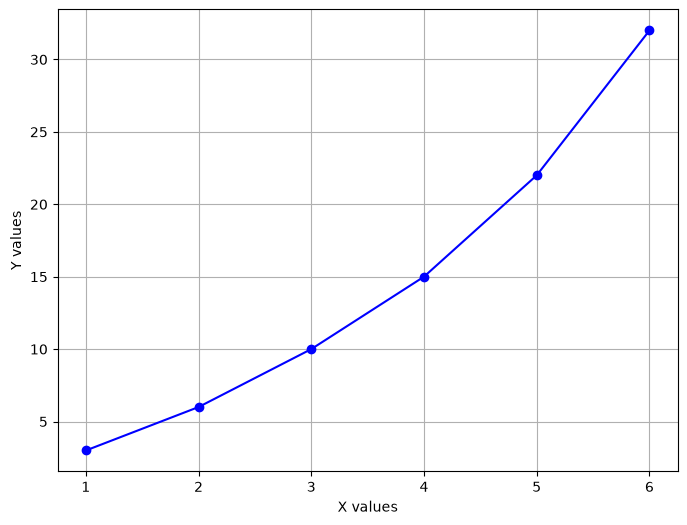

In [161]:
### Training with fancier version ###

import torch
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

import numpy as np

data = [(1.0,3.0), (2.0,6.0), (3.0,10.0), (4.0,15.0), (5.0,22.0), (6.0,32.0)]

# Split data into x and y
x_values, y_values = zip(*data)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o', linestyle='-', color='b')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.grid(True)
plt.show()

In [162]:
x = torch.FloatTensor([d[0] for d in data]).reshape(-1, 1)
y = torch.FloatTensor([d[1] for d in data]).reshape(-1, 1)

x_mean, x_std = x.mean(), x.std()
y_mean, y_std = y.mean(), y.std()
inputs  = (x - x_mean) / x_std
targets = (y - y_mean) / y_std

class Net(nn.Module):
    def __init__(self, n_features=2):
        super().__init__()
        self.fc1 = nn.Linear(n_features, 4)   
        self.fc2 = nn.Linear(4, 1)

    def forward(self, x):
        x = torch.cat([x, x**2], dim=1)
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

net = Net(n_features=2)

print(net)
print(list(net.parameters())) # parameters are randomized

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(net.parameters(), lr=0.01)


for epoch in range(2000):
    optimizer.zero_grad()   
    outputs = net(inputs)
    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()    ## This line is equivalent to "W = W - lr* W.grad"
    if epoch % 100 == 0:
        print("Epoch {} - loss: {}".format(epoch, loss))


### Test the trained network ###            
for i, current_data in enumerate(data):
    X, Y = current_data
    X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])  
    X = ((X - x_mean) / x_std).reshape(1, 1)
    out = net(X) * y_std + y_mean
    print("when x = {}, y = {}".format(X, out))



Net(
  (fc1): Linear(in_features=2, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=1, bias=True)
)
[Parameter containing:
tensor([[ 0.2085, -0.2746],
        [-0.3622,  0.4544],
        [-0.5880, -0.5621],
        [ 0.1933, -0.2382]], requires_grad=True), Parameter containing:
tensor([ 0.6574,  0.2202, -0.5501, -0.4382], requires_grad=True), Parameter containing:
tensor([[-0.1385,  0.1778, -0.4398,  0.1873]], requires_grad=True), Parameter containing:
tensor([-0.1910], requires_grad=True)]
Epoch 0 - loss: 0.7488197684288025
Epoch 100 - loss: 0.01137737836688757
Epoch 200 - loss: 0.0030492888763546944
Epoch 300 - loss: 0.00032822461798787117
Epoch 400 - loss: 4.7162495320662856e-05
Epoch 500 - loss: 9.577378477843013e-06
Epoch 600 - loss: 2.7685055101756006e-06
Epoch 700 - loss: 1.5252365983542404e-06
Epoch 800 - loss: 1.1643195421129349e-06
Epoch 900 - loss: 9.359590080748603e-07
Epoch 1000 - loss: 7.457276183231443e-07
Epoch 1100 - loss: 5.839667096552148e-07
E

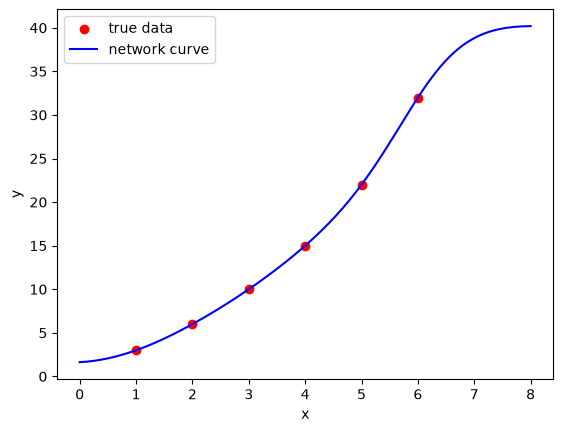

In [163]:
x_dense = torch.linspace(0, 8, 200).reshape(-1, 1)       # includes values beyond the data
x_dense_n = (x_dense - x_mean) / x_std

with torch.no_grad():
    y_dense = net(x_dense_n) * y_std + y_mean

plt.scatter(x_values, y_values, color="red", label="true data")
plt.plot(x_dense.numpy(), y_dense.numpy(), color="blue", label="network curve")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()